# HDB Rentals: EDA of `data/auxiliary/sg-hdb-block.csv`

This is the address crosswalk. It joins to `train.csv` / `test.csv` on `(TOWN, BLOCK, STREET)` and
adds coordinates, building attributes, and a geography finer than `TOWN`.

Do **not** put `n_primary_within_1km` or `n_mrt_within_1km` here. Those need school and MRT
coordinates and are built in `03_feature_rmse.ipynb`.

1. Why this table exists
2. Structure: shape, dtypes, missingness, duplicates
3. `.describe()` for numeric and categorical columns
4. Data-quality issues
5. A cleaned analysis frame
6. Join coverage against train/test
7. Geography and building attributes
8. Summary


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA = ROOT / "data"
AUX = DATA / "auxiliary"
CLEANED = ROOT / "cleaned"
OUT = ROOT / "outputs"
OUT_DIR = OUT
CLEANED.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

SG_LAT = (1.13, 1.47)
SG_LON = (103.6, 104.1)


def column_profile(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for c in df.columns:
        s = df[c]
        rows.append(
            {
                "dtype": str(s.dtype),
                "n_unique": s.nunique(dropna=True),
                "unique_pct": 100 * s.nunique(dropna=True) / len(s),
                "n_missing": s.isna().sum(),
                "missing_pct": 100 * s.isna().mean(),
                "examples": ", ".join(map(str, s.dropna().unique()[:4])),
            }
        )
    return pd.DataFrame(rows, index=df.columns)


def lower_strip(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    text = out.select_dtypes(include=["object", "string"]).columns
    out[text] = out[text].apply(lambda s: s.astype(str).str.strip().str.lower())
    return out

hdb_raw = pd.read_csv(AUX / "sg-hdb-block.csv", dtype={"POSTAL_CODE": "string"})
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
print(f"hdb: {hdb_raw.shape}   train: {train.shape}   test: {test.shape}")
hdb_raw.head()


hdb: (9464, 11)   train: (150000, 11)   test: (50000, 10)


,TOWN,BLOCK,STREET,POSTAL_CODE,LATITUDE,LONGITUDE,MAX_FLOOR,YEAR_COMPLETED,SUBZONE,PLANNING_AREA,REGION
0,serangoon,106,serangoon north avenue 1,550106,1.370,103.871,12,1983,serangoon garden,serangoon,north-east region
1,bukit merah,34,telok blangah way,090034,1.274,103.822,14,1975,telok blangah rise,bukit merah,central region
2,punggol,226b,sumang lane,822226,1.403,103.894,17,2016,matilda,punggol,north-east region
3,marine parade,74,marine drive,440074,1.304,103.907,14,1975,marine parade,marine parade,central region
4,choa chu kang,284,choa chu kang avenue 3,NIL,1.380,103.742,16,1990,keat hong,choa chu kang,west region


## 1. Why this table exists

Rental rows have a town, block and street, but no coordinates, no floor count and no planning area.
This file is the lookup for those fields. If the join key is dirty, every downstream MRT / school
feature that travels through `PLANNING_AREA` is dirty too — so this notebook cleans the crosswalk
before anything is merged onto rent.


In [2]:
print("join key: (TOWN, BLOCK, STREET)")
print("columns that travel onto a rental row:")
print([c for c in hdb_raw.columns if c not in {"TOWN", "BLOCK", "STREET"}])


join key: (TOWN, BLOCK, STREET)
columns that travel onto a rental row:
['POSTAL_CODE', 'LATITUDE', 'LONGITUDE', 'MAX_FLOOR', 'YEAR_COMPLETED', 'SUBZONE', 'PLANNING_AREA', 'REGION']


## 2. Structure, dtypes and missingness

Cardinality and example values per column. `isnull()` only sees real NaNs — sentinel placeholders
are checked in section 4.


In [3]:
hdb_raw.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9464 entries, 0 to 9463
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   TOWN            9464 non-null   object 
 1   BLOCK           9464 non-null   object 
 2   STREET          9464 non-null   object 
 3   POSTAL_CODE     9464 non-null   string 
 4   LATITUDE        9464 non-null   float64
 5   LONGITUDE       9464 non-null   float64
 6   MAX_FLOOR       9464 non-null   int64  
 7   YEAR_COMPLETED  9464 non-null   int64  
 8   SUBZONE         9464 non-null   object 
 9   PLANNING_AREA   9464 non-null   object 
 10  REGION          9464 non-null   object 
dtypes: float64(2), int64(2), object(6), string(1)
memory usage: 813.4+ KB


In [4]:
profile = column_profile(hdb_raw)
profile


,dtype,n_unique,unique_pct,n_missing,missing_pct,examples
TOWN,object,26,0.275,0,0.000,"serangoon, bukit merah, punggol, marine parade"
BLOCK,object,2735,28.899,0,0.000,"106, 34, 226b, 74"
STREET,object,576,6.086,0,0.000,"serangoon north avenue 1, telok blangah way, sumang lane, marine drive"
POSTAL_CODE,string,9180,96.999,0,0.000,"550106, 090034, 822226, 440074"
LATITUDE,float64,9049,95.615,0,0.000,"1.370245, 1.273518, 1.402685, 1.303705"
LONGITUDE,float64,9258,97.823,0,0.000,"103.870823, 103.822481, 103.893609, 103.907214"
MAX_FLOOR,int64,44,0.465,0,0.000,"12, 14, 17, 16"
YEAR_COMPLETED,int64,63,0.666,0,0.000,"1983, 1975, 2016, 1990"
SUBZONE,object,156,1.648,0,0.000,"serangoon garden, telok blangah rise, matilda, marine parade"
PLANNING_AREA,object,31,0.328,0,0.000,"serangoon, bukit merah, punggol, marine parade"


In [5]:
print("fully duplicated rows:", hdb_raw.duplicated().sum())
print("duplicated join keys:", hdb_raw.duplicated(["TOWN", "BLOCK", "STREET"]).sum())


fully duplicated rows: 0
duplicated join keys: 0


## 3. `.describe()`

Numeric and categorical columns are described separately.


In [6]:
num_cols = hdb_raw.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in hdb_raw.columns if c not in num_cols]
print("numeric    :", num_cols)
print("categorical:", cat_cols)

hdb_raw[num_cols].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T


numeric    : ['LATITUDE', 'LONGITUDE', 'MAX_FLOOR', 'YEAR_COMPLETED']
categorical: ['TOWN', 'BLOCK', 'STREET', 'POSTAL_CODE', 'SUBZONE', 'PLANNING_AREA', 'REGION']


,count,mean,std,min,1%,25%,50%,75%,99%,max
LATITUDE,"9,464.000",1.367,0.042,1.270,1.277,1.339,1.364,1.393,1.451,1.457
LONGITUDE,"9,464.000",103.841,0.074,103.685,103.694,103.774,103.846,103.900,103.961,103.988
MAX_FLOOR,"9,464.000",14.295,5.989,-1.000,4.000,12.000,13.000,16.000,40.000,50.000
YEAR_COMPLETED,"9,464.000","1,989.842",69.139,-1.000,"1,963.000","1,984.000","1,991.000","1,999.000","2,019.000","2,021.000"


In [7]:
hdb_raw[cat_cols].describe().T


,count,unique,top,freq
TOWN,9464,26,tampines,761
BLOCK,9464,2735,111,27
STREET,9464,576,yishun ring road,140
POSTAL_CODE,9464,9180,NIL,285
SUBZONE,9464,156,tampines east,414
PLANNING_AREA,9464,31,tampines,761
REGION,9464,5,west region,2320


## 4. Data-quality issues

Four things are not visible from `info()` / `isnull()` alone.


In [8]:
# (a) -1 is a missing-value placeholder, not a real floor or year.
for c in ["MAX_FLOOR", "YEAR_COMPLETED"]:
    n = (hdb_raw[c] == -1).sum()
    print(f"{c:<16} min={hdb_raw[c].min():>6}  n_eq_-1={n}")

missing_blocks = hdb_raw[(hdb_raw["MAX_FLOOR"] == -1) | (hdb_raw["YEAR_COMPLETED"] == -1)]
print(f"\nblocks with sentinel -1: {len(missing_blocks)}")
missing_blocks[["TOWN", "BLOCK", "STREET", "MAX_FLOOR", "YEAR_COMPLETED"]]


MAX_FLOOR        min=    -1  n_eq_-1=11
YEAR_COMPLETED   min=    -1  n_eq_-1=11

blocks with sentinel -1: 11


,TOWN,BLOCK,STREET,MAX_FLOOR,YEAR_COMPLETED
2859,queenstown,30,tanglin halt road,-1,-1
3400,geylang,82,macpherson lane,-1,-1
4113,clementi,518,west coast road,-1,-1
4385,queenstown,63,commonwealth drive,-1,-1
5391,clementi,514,west coast road,-1,-1
5525,clementi,515,west coast road,-1,-1
5550,queenstown,55,commonwealth drive,-1,-1
6501,clementi,513,west coast road,-1,-1
7764,queenstown,40,tanglin halt road,-1,-1
8238,clementi,519,west coast road,-1,-1


In [9]:
# (b) POSTAL_CODE stores the string "NIL" for 285 blocks — also invisible to isnull().
postal = hdb_raw["POSTAL_CODE"].astype(str).str.strip()
n_nil = postal.str.upper().eq("NIL").sum()
print(f"POSTAL_CODE == 'NIL': {n_nil} rows  (isnull reports {hdb_raw['POSTAL_CODE'].isna().sum()})")
hdb_raw.loc[postal.str.upper().eq("NIL"), ["TOWN", "BLOCK", "STREET", "POSTAL_CODE"]].head(8)


POSTAL_CODE == 'NIL': 285 rows  (isnull reports 0)


,TOWN,BLOCK,STREET,POSTAL_CODE
4,choa chu kang,284,choa chu kang avenue 3,NIL
17,toa payoh,158,lorong 1 toa payoh,NIL
66,jurong west,274d,jurong west avenue 3,NIL
82,jurong west,725,jurong west avenue 5,NIL
234,bukit merah,113,bukit purmei road,NIL
240,yishun,160,yishun street 11,NIL
259,toa payoh,97,lorong 3 toa payoh,NIL
319,woodlands,715,woodlands drive 70,NIL


In [10]:
# (c) Coordinates should sit inside Singapore.
bad_coords = hdb_raw[
    ~hdb_raw["LATITUDE"].between(*SG_LAT) | ~hdb_raw["LONGITUDE"].between(*SG_LON)
]
print(f"out-of-bounds coordinates: {len(bad_coords)}")


out-of-bounds coordinates: 0


In [11]:
# (d) TOWN is not 1:1 with PLANNING_AREA. A few towns split, which later explains "zero school" areas.
split = (
    hdb_raw.groupby("TOWN")["PLANNING_AREA"]
    .nunique()
    .loc[lambda s: s > 1]
    .sort_values(ascending=False)
)
print("towns that span more than one planning area:")
print(split.to_string())
print()
(
    hdb_raw[hdb_raw["TOWN"].isin(split.index)]
    .groupby(["TOWN", "PLANNING_AREA"])
    .size()
    .rename("n_blocks")
    .reset_index()
    .sort_values(["TOWN", "n_blocks"], ascending=[True, False])
)


towns that span more than one planning area:
TOWN
kallang/whampoa    4
central            3
bukit timah        2
hougang            2
pasir ris          2
queenstown         2



,TOWN,PLANNING_AREA,n_blocks
0,bukit timah,bukit timah,24
1,bukit timah,tanglin,2
4,central,rochor,33
3,central,outram,29
2,central,downtown core,2
5,hougang,hougang,559
6,hougang,serangoon,1
9,kallang/whampoa,kallang,184
10,kallang/whampoa,novena,62
7,kallang/whampoa,bukit timah,1


The 11 sentinel blocks are not scattered: they sit on a handful of streets (Queenstown, Clementi,
Geylang). In the rental file those addresses stop appearing after 2023, which is consistent with
SERS / redevelopment vacancy rather than a random hole. They are flagged in the cleaned frame, not
dropped. `MAX_FLOOR` is left missing; there is no reliable proxy for height.


## 5. A cleaned analysis frame

Only the repairs above: lowercase keys, `-1` → `<NA>`, `"NIL"` postal codes → `<NA>`, a
missing-info flag. `MAX_FLOOR` stays missing for the 11 SERS blocks. No median (or other) fill
in this table. LightGBM can leave those NaNs as missing later. Linear Regression only fills a
median if `MAX_FLOOR` is actually in that model.


In [12]:
KEY = ["TOWN", "BLOCK", "STREET"]


def clean_hdb(df: pd.DataFrame) -> pd.DataFrame:
    out = lower_strip(df)
    for c in ["MAX_FLOOR", "YEAR_COMPLETED"]:
        out[c] = pd.to_numeric(out[c], errors="coerce").replace(-1, np.nan).astype("Int64")
    out["POSTAL_CODE"] = out["POSTAL_CODE"].replace({"nil": pd.NA})
    out["LATITUDE"] = pd.to_numeric(out["LATITUDE"], errors="coerce")
    out["LONGITUDE"] = pd.to_numeric(out["LONGITUDE"], errors="coerce")
    out["MISSING_BUILDING_INFO"] = out["MAX_FLOOR"].isna() | out["YEAR_COMPLETED"].isna()
    out = out.drop_duplicates(subset=KEY, keep="first").reset_index(drop=True)
    return out


hdb = clean_hdb(hdb_raw)
print(hdb.shape)
print("missing after sentinel cleanup:")
print(hdb[["MAX_FLOOR", "YEAR_COMPLETED", "POSTAL_CODE"]].isna().sum())
hdb.head(3)


(9464, 12)
missing after sentinel cleanup:
MAX_FLOOR          11
YEAR_COMPLETED     11
POSTAL_CODE       285
dtype: int64


,TOWN,BLOCK,STREET,POSTAL_CODE,LATITUDE,LONGITUDE,MAX_FLOOR,YEAR_COMPLETED,SUBZONE,PLANNING_AREA,REGION,MISSING_BUILDING_INFO
0,serangoon,106,serangoon north avenue 1,550106,1.370,103.871,12,1983,serangoon garden,serangoon,north-east region,False
1,bukit merah,34,telok blangah way,090034,1.274,103.822,14,1975,telok blangah rise,bukit merah,central region,False
2,punggol,226b,sumang lane,822226,1.403,103.894,17,2016,matilda,punggol,north-east region,False


## 6. Join coverage against train/test

Train/test mix case on `STREET` (and sometimes `BLOCK`). Without a lowercase strip, the join
silently misses rows.


In [13]:
def coverage(rent: pd.DataFrame, blocks: pd.DataFrame, name: str) -> None:
    left = rent.merge(blocks[KEY], on=KEY, how="left", indicator=True)
    hit = (left["_merge"] == "both").mean()
    print(f"{name:<6} matched {hit:.2%}  ({len(rent):,} rows)")


print("raw keys (no case fold):")
coverage(train, hdb_raw, "train")
coverage(test, hdb_raw, "test")

train_k = lower_strip(train)
test_k = lower_strip(test)
print("\nnormalized keys:")
coverage(train_k, hdb, "train")
coverage(test_k, hdb, "test")


raw keys (no case fold):
train  matched 79.48%  (150,000 rows)
test   matched 79.04%  (50,000 rows)

normalized keys:
train  matched 100.00%  (150,000 rows)
test   matched 100.00%  (50,000 rows)


## 7. Geography and building attributes


,count,mean,std,min,25%,50%,75%,max
MAX_FLOOR,"9,453.000",14.312,5.970,2.000,12.000,13.000,16.000,50.000
YEAR_COMPLETED,"9,453.000","1,992.158",12.952,"1,949.000","1,984.000","1,991.000","1,999.000","2,021.000"
LATITUDE,"9,464.000",1.367,0.042,1.270,1.339,1.364,1.393,1.457
LONGITUDE,"9,464.000",103.841,0.074,103.685,103.774,103.846,103.900,103.988


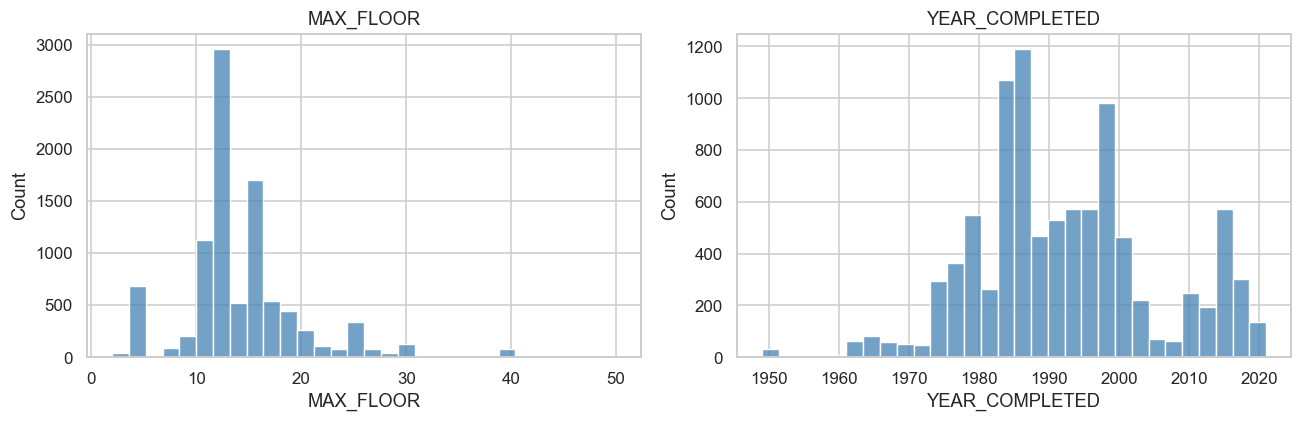

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(hdb["MAX_FLOOR"].astype("float"), bins=30, ax=axes[0], color="steelblue")
axes[0].set_title("MAX_FLOOR")
sns.histplot(hdb["YEAR_COMPLETED"].astype("float"), bins=30, ax=axes[1], color="steelblue")
axes[1].set_title("YEAR_COMPLETED")
plt.tight_layout()
plt.show()

hdb[["MAX_FLOOR", "YEAR_COMPLETED", "LATITUDE", "LONGITUDE"]].describe().T


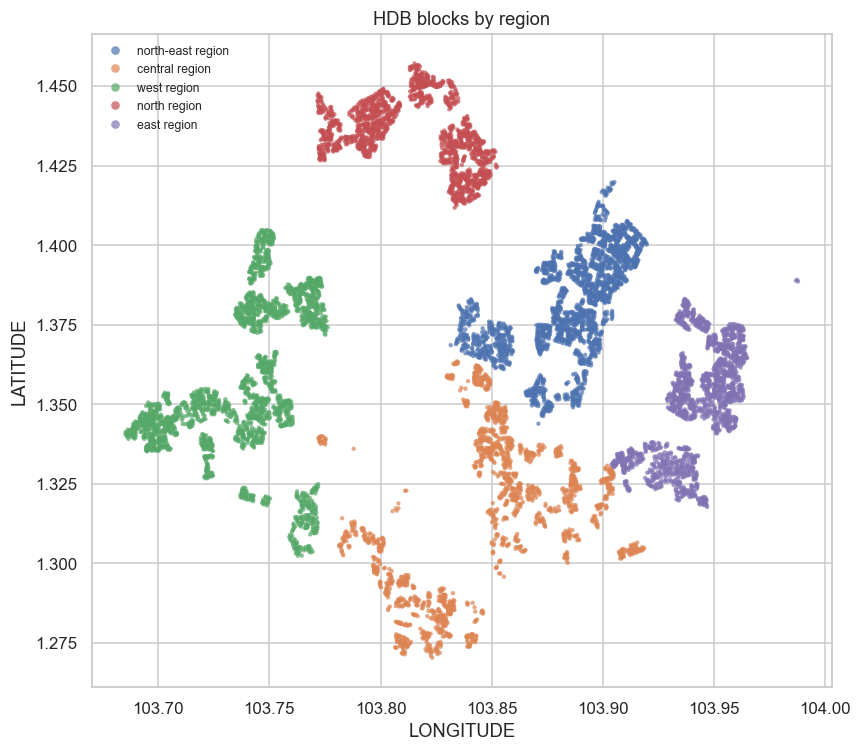

In [15]:
fig, ax = plt.subplots(figsize=(8, 7))
sns.scatterplot(
    data=hdb, x="LONGITUDE", y="LATITUDE", hue="REGION",
    s=8, linewidth=0, alpha=0.7, ax=ax,
)
ax.set_title("HDB blocks by region")
ax.legend(loc="upper left", fontsize=8, markerscale=2, frameon=False)
plt.tight_layout()
plt.show()


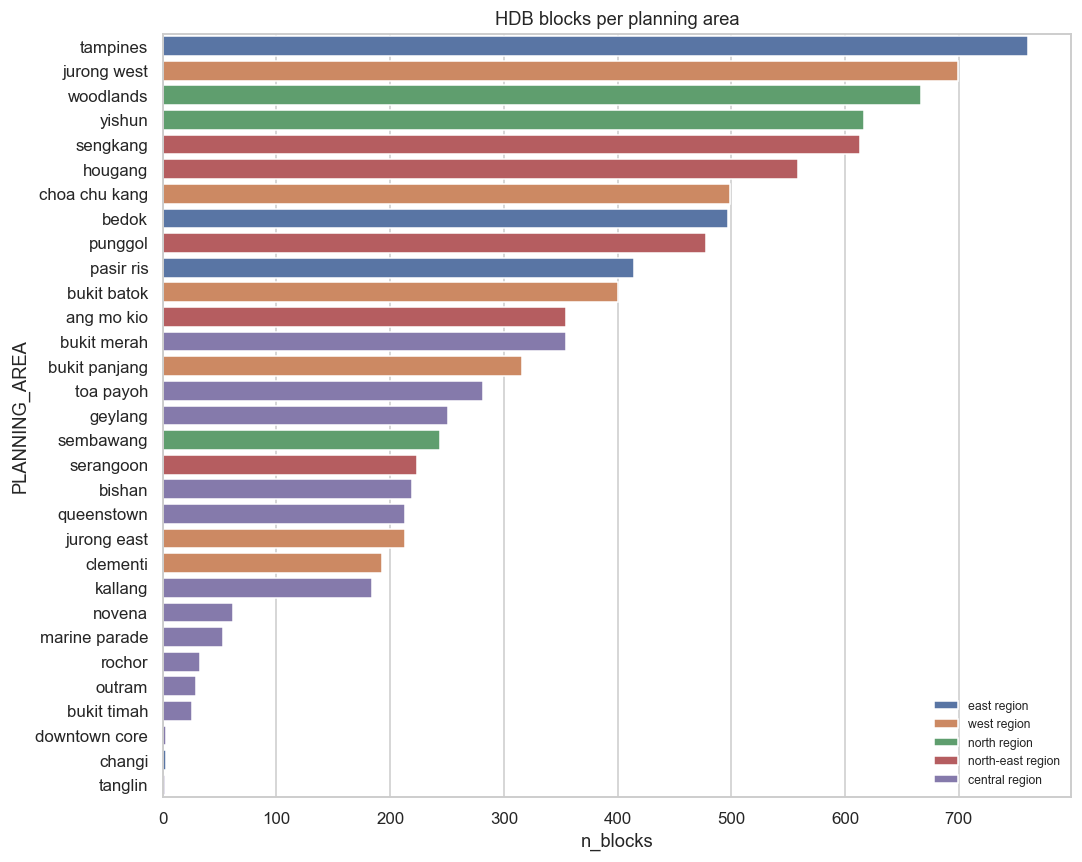

In [16]:
area = (
    hdb.groupby(["REGION", "PLANNING_AREA"], observed=True)
    .size()
    .rename("n_blocks")
    .reset_index()
    .sort_values("n_blocks", ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(data=area, y="PLANNING_AREA", x="n_blocks", hue="REGION", dodge=False, ax=ax)
ax.set_title("HDB blocks per planning area")
ax.legend(loc="lower right", fontsize=8, frameon=False)
plt.tight_layout()
plt.show()


In [17]:
print("REGION")
print(hdb["REGION"].value_counts(), "\n")
print(f"TOWN={hdb['TOWN'].nunique()}  PLANNING_AREA={hdb['PLANNING_AREA'].nunique()}  "
      f"SUBZONE={hdb['SUBZONE'].nunique()}")


REGION
REGION
west region          2320
north-east region    2229
central region       1712
east region          1675
north region         1528
Name: count, dtype: int64 

TOWN=26  PLANNING_AREA=31  SUBZONE=156


## 8. Summary

- **Role:** block-level lookup for coordinates, `MAX_FLOOR`, `YEAR_COMPLETED`, `SUBZONE` /
  `PLANNING_AREA` / `REGION`.
- **Join:** `(TOWN, BLOCK, STREET)` is unique. Train/test must be lowercased or coverage falls from
  100% to ~79%. After lowercase the match is 100%.
- **Missingness:** `isnull()` reports none; `-1` hides 11 SERS blocks and `"NIL"` hides 285 postcodes.
  Flag `MISSING_BUILDING_INFO`. Leave `MAX_FLOOR` as NaN. Do not impute height in this table.
- **Geography:** 26 towns, 31 planning areas, 5 regions. A few towns split across planning areas
  (`kallang/whampoa`, `central`, …).
- **Not in this notebook:** 1 km school / MRT counts. Those are in `03_feature_rmse.ipynb`.
- **Next:** `01_eda_mrt.ipynb`, `01_eda_school.ipynb`, then `03_feature_rmse.ipynb`.


In [18]:
hdb.to_csv(CLEANED / "sg_hdb_block_cleaned.csv", index=False)

feature_cols = KEY + [
    "LATITUDE", "LONGITUDE", "MAX_FLOOR", "YEAR_COMPLETED",
    "SUBZONE", "PLANNING_AREA", "REGION", "MISSING_BUILDING_INFO",
]
hdb[feature_cols].to_csv(OUT / "hdb_block_features.csv", index=False)

hdb_blocks_by_area = (
    hdb.groupby("PLANNING_AREA").size().rename("n_hdb_blocks").reset_index()
)
hdb_blocks_by_area.to_csv(OUT / "hdb_blocks_by_area.csv", index=False)

print("wrote", CLEANED / "sg_hdb_block_cleaned.csv", hdb.shape)
print("wrote", OUT / "hdb_block_features.csv")
print("wrote", OUT / "hdb_blocks_by_area.csv", hdb_blocks_by_area.shape)


wrote ../cleaned/sg_hdb_block_cleaned.csv (9464, 12)
wrote ../outputs/hdb_block_features.csv
wrote ../outputs/hdb_blocks_by_area.csv (31, 2)
